# TE mode and Bessel functions
![Fig. 6](../.figure/fig6.jpg)


This notebook contains the explanations, figures, and executable code in one file. Run the code from top to bottom. After changing a value, press Shift+Enter to run the cell again.


## 1. Coordinates and the wave vector

Let the cylindrical coordinates be

$$
(r,\phi,z)
$$

where

- $z$: the axial direction of the waveguide
- $r$: the distance from the axis
- $\phi$: the azimuthal angle in the cross section

For each plane-wave component in a uniform core, the wave vector can be separated into axial and transverse components:

$$
\mathbf{k}=\mathbf{k}_\perp+\beta \hat z
$$

In a discussion of cylindrical symmetry, we write the magnitude of the transverse wave vector as $k_r$ and set

$$
k_r=nk_0\sin\theta,\qquad
\beta=nk_0\cos\theta
$$

Here, $\theta$ is the angle between the wave vector $\mathbf{k}$ and the $z$ axis. Thus, $\theta$ tells us how much the wave is tilted relative to the waveguide axis.


In [1]:
# To run the plots, start with this cell.
import numpy as np
import matplotlib.pyplot as plt

# Compute J0 and J1 numerically by angular averaging, without SciPy.
# Integral representation of J0: https://dlmf.nist.gov/10.9#E1
# J1 = the negative derivative of J0: https://dlmf.nist.gov/10.6#E3
def j0(x):
    x = np.asarray(x, dtype=float)[..., None]
    n = max(256, int(4*np.max(np.abs(x))) + 32)
    psi = np.linspace(0, 2*np.pi, n, endpoint=False)
    return np.cos(x*np.cos(psi)).mean(axis=-1)

def j1(x):
    x = np.asarray(x, dtype=float)[..., None]
    n = max(256, int(4*np.max(np.abs(x))) + 32)
    psi = np.linspace(0, 2*np.pi, n, endpoint=False)
    return (np.cos(psi)*np.sin(x*np.cos(psi))).mean(axis=-1)

k_r = 1.0     # Transverse wave number: try changing this value.
r_max = 10.0  # Radial range shown in the plots
r = np.linspace(0, r_max, 500)


## 2. What a TE mode means

A TE mode has no axial electric-field component; that is, it satisfies

$$
E_z=0
$$

The electric field in the waveguide is therefore parallel to the fiber cross section.
Also, since

$$
\mathbf{k}=\mathbf{k}_\perp+\beta \hat z
$$

we have, for each plane-wave component in a uniform medium, $\mathbf{k} \cdot \mathbf{E} = \mathbf{k}_\perp \cdot \mathbf{E} + \beta \hat z  \cdot \mathbf{E} = \mathbf{k}_\perp \cdot \mathbf{E} = 0$

In other words, $\mathbf{E}$ is perpendicular to the plane formed by $\mathbf{k}$ and $\mathbf{k}_\perp$.

If we write

$$
\mathbf{k}_\perp = k_r \hat {\mathbf {r}}
$$

then the electric field points in the $\hat{\boldsymbol\phi}$ direction.

This description of the polarization direction applies to each plane-wave component. Section 6 discusses the electric field of the mode formed by adding these components.


## 3. An intuitive picture: superposing reflected plane waves
![Fig. 13](../.figure/fig13.jpg)

A mode in a waveguide can be understood intuitively as a superposition of plane-wave components that share the same axial component $\beta$ but have different transverse azimuthal directions. For example, one component can be written as

$$
\mathbf{k}=k_r\hat r+\beta \hat z
$$

For a plane wave in a uniform medium,

$$
\mathbf{E}\cdot \mathbf{k}=0
$$

so the electric field must be perpendicular to $\mathbf{k}$. In cylindrical coordinates, an electric field in the $\hat\phi$ direction is perpendicular to both $\hat r$ and $\hat z$, making it easy to picture a TE-like polarization.

If we consider reflection in one transverse direction, as in the figure, the wave-vector component in that direction changes as

$$
k_r\rightarrow -k_r
$$

while $\beta$ remains unchanged. Keeping the notation of the original figure, let us compare the two components along one chosen radial direction. If we give them equal amplitudes and omit their relative phase difference,

$$
e^{i(k_r r+\beta z)}+e^{i(-k_r r+\beta z)}
=
2\cos(k_r r)e^{i\beta z}
$$

The superposition of the $\pm k_r$ components therefore produces a transverse standing-wave pattern. The average below refers to the two signed components $+k_r$ and $-k_r$, not to their magnitude. In this sense,

$$
\langle k_r\rangle=0,\qquad k_r\neq 0
$$

That is, **there is no average transverse flow, but a transverse length scale remains, producing a mode pattern across the cross section**.

Here, $\cos(k_r r)$ is **a one-dimensional example viewed along a single direction**.
It does not yet represent a cylindrical-wave solution over the entire cross section.
Think of this superposition as describing the spatial dependence of a scalar field component such as $H_z$.

**Now let us rotate this direction within the cross section and add the contributions from all azimuthal angles.**
The phase of each wave then involves not simply the distance $r$, but the projection of the observation-point position onto that wave's direction of travel.
In the next section, we will see how this procedure gives rise to a Bessel function.


### Explore: superposition of two waves

Run the next cell with **Shift+Enter**, move the time slider, and click a plot to inspect the values at a point.
The **instantaneous field** is the electric field at the selected time; **amplitude** is its maximum absolute value over one period at that point.

Here, $x$ is a signed coordinate along one chosen transverse direction. The display units are $\lambda_x=2\pi/k_r$, $\lambda_z=2\pi/\beta$, and $T=2\pi/\omega$.
No separate file or SciPy installation is needed. Static previews are not interactive; run the cell in Jupyter.


In [4]:
# The interface is embedded in this cell; no external file is read.
from IPython.display import HTML, display
from html import escape

TE_WAVE_HTML = r"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Component waves and sum</title>
<style>
:root {
  color-scheme: light dark;
  --background: light-dark(rgb(255 255 255), rgb(24 24 24));
  --foreground: light-dark(rgb(26 28 31), rgb(255 255 255));
  --border: light-dark(rgb(26 28 31 / 12%), rgb(255 255 255 / 15%));
  --viz-series-1: light-dark(rgb(51 156 255), rgb(131 195 255));
  --viz-series-2: light-dark(rgb(243 136 59), rgb(245 154 86));
  --viz-series-3: light-dark(rgb(93 201 119), rgb(116 213 139));
  --viz-series-4: light-dark(rgb(235 119 177), rgb(240 143 192));
}
* { box-sizing: border-box; }
html, body { margin: 0; background: var(--background); color: var(--foreground); }
body { padding: 12px; font: 16px/1.5 system-ui, 'Segoe UI', sans-serif; }
h3 { font-size: 20px; line-height: 1.5; font-weight: 500; margin: 0 0 8px; }
.text-small { font-size: 14px; line-height: 1.5; }
.tabular-nums { font-variant-numeric: tabular-nums; }
.form-label { display: block; }
.form-range { display: block; width: 100%; height: 24px; margin: 0; accent-color: var(--foreground); }
.cursor-interaction { cursor: crosshair; }
</style>
</head>
<body>
<div id="wave-quantities">
  <style>
    #wave-quantities { color: var(--foreground); }
    #wave-quantities h3 { padding-right: 90px; }
    #wave-quantities .wq-control { margin: 6px 0; }
    #wave-quantities .wq-between { display: flex; justify-content: space-between; gap: 8px; flex-wrap: wrap; }
    #wave-quantities .wq-panels { display: grid; grid-template-columns: repeat(2, minmax(0, 1fr)); gap: 10px 16px; }
    #wave-quantities .wq-sum { grid-column: 1 / -1; }
    #wave-quantities .wq-panel { min-width: 0; }
    #wave-quantities .wq-panel canvas { display: block; width: 100%; height: 120px; }
    #wave-quantities .wq-title { display: flex; justify-content: space-between; gap: 6px; flex-wrap: wrap; }
    #wave-quantities .wq-scale { display: flex; align-items: center; gap: 8px; }
    #wave-quantities .wq-ramp { height: 10px; flex: 1; min-width: 36px; }
    #wave-quantities .wq-field-ramp { background: linear-gradient(to right, var(--viz-series-2), var(--background), var(--viz-series-1)); }
    #wave-quantities .wq-positive-ramp { background: linear-gradient(to right, var(--background), var(--viz-series-1)); }
    #wave-quantities .wq-phase-ramp { background: linear-gradient(to right, var(--viz-series-1), var(--viz-series-4), var(--viz-series-2), var(--viz-series-3), var(--viz-series-1)); }
    #wave-quantities .wq-phase-ticks { display: flex; justify-content: space-between; }
    #wave-quantities .wq-node-key { display: inline-block; width: 24px; border-top: 1px dashed var(--foreground); vertical-align: middle; margin-right: 6px; }
    #wave-quantities .wq-selected { margin: 4px 0 8px; }
    #wave-quantities .wq-probe { position: absolute; visibility: hidden; }
    @media (max-width: 640px) {
      #wave-quantities .wq-panels { grid-template-columns: minmax(0, 1fr); }
      #wave-quantities .wq-panel canvas { height: 152px; }
    }
  </style>
  <h3>Component waves and sum</h3>
  <div class="wq-control">
    <div class="wq-between">
      <label class="form-label" for="wq-time">Time</label>
      <output id="wq-time-value" class="tabular-nums" aria-live="polite">t/T = 0.00</output>
    </div>
    <input id="wq-time" class="form-range" type="range" min="0" max="1" step="0.01" value="0" aria-label="Time t/T">
  </div>
  <div class="wq-selected text-small tabular-nums" id="wq-position">Selected: x/λₓ = 0.00, z/λz = 0.00 · Click a plot to select</div>
  <div class="wq-panels">
    <section class="wq-panel">
      <div class="wq-title"><span>Incident instantaneous field E₁/E₀</span><output id="wq-incident-value" class="tabular-nums">1.00</output></div>
      <canvas id="wq-incident" class="cursor-interaction" role="img" aria-label="Instantaneous incident electric field. The wave travels in the positive x and positive z directions.">Instantaneous incident electric field</canvas>
      <div class="wq-scale text-small"><span>−2</span><span class="wq-ramp wq-field-ramp"></span><span>+2</span></div>
    </section>
    <section class="wq-panel">
      <div class="wq-title"><span>Reflected instantaneous field E₂/E₀</span><output id="wq-reflected-value" class="tabular-nums">1.00</output></div>
      <canvas id="wq-reflected" class="cursor-interaction" role="img" aria-label="Instantaneous reflected electric field. The wave travels in the negative x and positive z directions.">Instantaneous reflected electric field</canvas>
      <div class="wq-scale text-small"><span>−2</span><span class="wq-ramp wq-field-ramp"></span><span>+2</span></div>
    </section>
    <section class="wq-panel wq-sum">
      <div class="wq-title"><span>Total instantaneous field (E₁ + E₂)/E₀</span><output id="wq-field-value" class="tabular-nums">2.00</output></div>
      <canvas id="wq-field" class="cursor-interaction" role="img" aria-label="Instantaneous total electric field. Horizontal position is axial; vertical position is transverse. Its sign and magnitude change with time.">Instantaneous total electric field</canvas>
      <div class="wq-scale text-small"><span>−2</span><span class="wq-ramp wq-field-ramp"></span><span>+2</span></div>
    </section>
    <section class="wq-panel">
      <div class="wq-title"><span>Amplitude A/E₀ · peak</span><output id="wq-amplitude-value" class="tabular-nums">2.00</output></div>
      <canvas id="wq-amplitude" class="cursor-interaction" role="img" aria-label="Maximum absolute value of the total electric field over one period at a fixed position. It ranges from 0 to 2 and is independent of time in this model.">Total amplitude</canvas>
      <div class="wq-scale text-small"><span>0</span><span class="wq-ramp wq-positive-ramp"></span><span>2</span></div>
    </section>
    <section class="wq-panel">
      <div class="wq-title"><span>Phase Φ · time included</span><output id="wq-phase-value" class="tabular-nums">0.00π</output></div>
      <canvas id="wq-phase" class="cursor-interaction" role="img" aria-label="Total phase, including the time term, displayed between minus pi and pi. Phase is undefined at nodes.">Total phase</canvas>
      <div class="wq-scale"><span class="wq-ramp wq-phase-ramp"></span></div>
      <div class="wq-phase-ticks text-small"><span>−π</span><span>−π/2</span><span>0</span><span>π/2</span><span>π</span></div>
    </section>
  </div>
  <div class="text-small" style="margin-top:12px"><span class="wq-node-key"></span>Dashed lines: nodes (A = 0) · phase undefined</div>
  <span id="wq-probe" class="wq-probe" aria-hidden="true"></span>
  <script>
  (() => {
    const root = document.getElementById('wave-quantities');
    const slider = root.querySelector('#wq-time');
    const probe = root.querySelector('#wq-probe');
    const tau = 2 * Math.PI;
    const nodes = [-0.75, -0.25, 0.25, 0.75];
    const plots = ['incident', 'reflected', 'field', 'amplitude', 'phase'].map(name => ({name, canvas: root.querySelector('#wq-' + name)}));
    const raster = document.createElement('canvas');
    raster.width = 256; raster.height = 128;
    const rasterContext = raster.getContext('2d');
    const colorCanvas = document.createElement('canvas');
    colorCanvas.width = colorCanvas.height = 1;
    const colorContext = colorCanvas.getContext('2d', {willReadFrequently: true});
    let time = 0;
    let selected = {x: 0, z: 0};
    let framePending = false;

    function waveAt(x, z, t) {
      const c = Math.cos(tau * x);
      const a = Math.cos(tau * (x + z - t));
      const b = Math.cos(tau * (-x + z - t));
      const isNode = Math.abs(c) < 1e-10;
      const amplitude = isNode ? 0 : 2 * Math.abs(c);
      const phase0 = tau * (z - t) + (c < 0 ? Math.PI : 0);
      const phase = isNode ? null : Math.atan2(Math.sin(phase0), Math.cos(phase0));
      return {incident: a, reflected: b, field: isNode ? 0 : a + b, amplitude, phase};
    }

    function color(token) {
      probe.style.color = 'var(' + token + ')';
      const css = getComputedStyle(probe).color;
      colorContext.clearRect(0, 0, 1, 1);
      colorContext.fillStyle = css;
      colorContext.fillRect(0, 0, 1, 1);
      return {css, rgb: Array.from(colorContext.getImageData(0, 0, 1, 1).data).slice(0, 3)};
    }
    function mix(a, b, amount) { return a.map((v, i) => Math.round(v * (1 - amount) + b[i] * amount)); }
    function phaseColor(phase, colors) {
      const p = Math.max(0, Math.min(4, (phase + Math.PI) / tau * 4));
      const i = Math.min(3, Math.floor(p));
      return mix(colors[i], colors[i + 1], p - i);
    }
    function fixed(value) { return Math.abs(value) < 0.0005 ? '0.00' : value.toFixed(2); }
    function updateValues() {
      const q = waveAt(selected.x, selected.z, time);
      root.querySelector('#wq-time-value').textContent = 't/T = ' + time.toFixed(2);
      slider.setAttribute('aria-valuetext', time.toFixed(2) + ' periods');
      root.querySelector('#wq-position').textContent = 'Selected: x/λₓ = ' + fixed(selected.x) + ', z/λz = ' + fixed(selected.z) + ' · Click a plot to select';
      for (const key of ['incident', 'reflected', 'field', 'amplitude']) root.querySelector('#wq-' + key + '-value').textContent = fixed(q[key]);
      root.querySelector('#wq-phase-value').textContent = q.phase === null ? 'Undefined' : fixed(q.phase / Math.PI) + 'π';
    }
    function render() {
      const positive = color('--viz-series-1');
      const negative = color('--viz-series-2');
      const base = color('--background');
      const foreground = color('--foreground');
      const border = color('--border');
      const phaseColors = [positive.rgb, color('--viz-series-4').rgb, negative.rgb, color('--viz-series-3').rgb, positive.rgb];
      updateValues();
      for (const plot of plots) {
        const width = Math.round(plot.canvas.getBoundingClientRect().width);
        if (width < 1) continue;
        const height = Math.round(plot.canvas.getBoundingClientRect().height);
        const left = 58, right = 10, top = 9, bottom = 35;
        const pw = width - left - right, ph = height - top - bottom;
        plot.geometry = {width, height, left, top, pw, ph};
        const image = rasterContext.createImageData(raster.width, raster.height);
        for (let row = 0; row < raster.height; row++) {
          const x = 1 - 2 * (row + 0.5) / raster.height;
          for (let col = 0; col < raster.width; col++) {
            const z = 2 * (col + 0.5) / raster.width;
            const q = waveAt(x, z, time);
            let rgb;
            if (plot.name === 'phase') rgb = q.phase === null ? base.rgb : phaseColor(q.phase, phaseColors);
            else if (plot.name === 'amplitude') rgb = mix(base.rgb, positive.rgb, q.amplitude / 2);
            else rgb = mix(base.rgb, q[plot.name] >= 0 ? positive.rgb : negative.rgb, Math.min(1, Math.abs(q[plot.name]) / 2));
            const index = 4 * (row * raster.width + col);
            image.data.set([rgb[0], rgb[1], rgb[2], 255], index);
          }
        }
        rasterContext.putImageData(image, 0, 0);
        const dpr = window.devicePixelRatio || 1;
        plot.canvas.width = Math.round(width * dpr); plot.canvas.height = Math.round(height * dpr);
        const ctx = plot.canvas.getContext('2d');
        ctx.setTransform(dpr, 0, 0, dpr, 0, 0);
        ctx.clearRect(0, 0, width, height);
        ctx.imageSmoothingEnabled = false;
        ctx.drawImage(raster, left, top, pw, ph);
        ctx.strokeStyle = border.css; ctx.lineWidth = 1; ctx.strokeRect(left, top, pw, ph);
        if (!['incident', 'reflected'].includes(plot.name)) {
          for (const x of nodes) {
            const y = top + (1 - x) / 2 * ph;
            if (plot.name === 'phase') { ctx.strokeStyle = base.css; ctx.lineWidth = 3; ctx.beginPath(); ctx.moveTo(left, y); ctx.lineTo(left + pw, y); ctx.stroke(); }
            ctx.strokeStyle = foreground.css; ctx.lineWidth = 1; ctx.setLineDash([3, 4]);
            ctx.beginPath(); ctx.moveTo(left, y); ctx.lineTo(left + pw, y); ctx.stroke(); ctx.setLineDash([]);
          }
        }
        const sx = left + selected.z / 2 * pw, sy = top + (1 - selected.x) / 2 * ph;
        ctx.save(); ctx.beginPath(); ctx.rect(left, top, pw, ph); ctx.clip();
        ctx.strokeStyle = base.css; ctx.lineWidth = 4;
        ctx.beginPath(); ctx.arc(sx, sy, 4, 0, tau); ctx.stroke();
        ctx.strokeStyle = foreground.css; ctx.lineWidth = 1.5;
        ctx.beginPath(); ctx.arc(sx, sy, 4, 0, tau); ctx.stroke(); ctx.restore();
        const style = getComputedStyle(root);
        ctx.font = style.fontSize + ' ' + style.fontFamily; ctx.fillStyle = foreground.css;
        ctx.textBaseline = 'middle'; ctx.textAlign = 'right';
        ctx.fillText('+1', left - 7, top + 6); ctx.fillText('0', left - 7, top + ph / 2); ctx.fillText('−1', left - 7, top + ph - 6);
        ctx.save(); ctx.translate(12, top + ph / 2); ctx.rotate(-Math.PI / 2); ctx.textAlign = 'center'; ctx.fillText('x/λₓ', 0, 0); ctx.restore();
        ctx.textAlign = 'left'; ctx.fillText('0', left, height - 15);
        ctx.textAlign = 'center'; ctx.fillText('z/λz →', left + pw / 2, height - 15);
        ctx.textAlign = 'right'; ctx.fillText('2', left + pw, height - 15);
      }
    }
    function scheduleRender() {
      if (!framePending) { framePending = true; requestAnimationFrame(() => { framePending = false; render(); }); }
    }
    function save() {
      if (window.openai && window.openai.setWidgetState) {
        const q = waveAt(selected.x, selected.z, time);
        window.openai.setWidgetState({modelContent: {timeOverPeriod: time, xOverLambdaX: selected.x, zOverLambdaZ: selected.z, incidentOverE0: q.incident, reflectedOverE0: q.reflected, fieldOverE0: q.field, amplitudeOverE0: q.amplitude, phaseOverPi: q.phase === null ? null : q.phase / Math.PI}, privateContent: {time, selected}}).catch(() => {});
      }
    }
    function restore(state) {
      const s = state && state.privateContent;
      if (s && Number.isFinite(s.time)) { time = Math.max(0, Math.min(1, s.time)); slider.value = String(time); }
      if (s && s.selected && Number.isFinite(s.selected.x) && Number.isFinite(s.selected.z)) selected = {x: Math.max(-1, Math.min(1, s.selected.x)), z: Math.max(0, Math.min(2, s.selected.z))};
    }
    restore(window.openai && window.openai.widgetState);
    slider.addEventListener('input', () => { time = Number(slider.value); scheduleRender(); });
    slider.addEventListener('change', save);
    for (const plot of plots) plot.canvas.addEventListener('click', event => {
      const g = plot.geometry; if (!g) return;
      const box = plot.canvas.getBoundingClientRect();
      const px = (event.clientX - box.left) * g.width / box.width;
      const py = (event.clientY - box.top) * g.height / box.height;
      if (px < g.left || px > g.left + g.pw || py < g.top || py > g.top + g.ph) return;
      let x = 1 - 2 * (py - g.top) / g.ph;
      for (const node of nodes) if (Math.abs(x - node) * g.ph / 2 < 3) { x = node; break; }
      selected = {x, z: 2 * (px - g.left) / g.pw}; scheduleRender(); save();
    });
    window.addEventListener('openai:set_globals', event => { const g = event.detail && event.detail.globals; if (g && Object.prototype.hasOwnProperty.call(g, 'widgetState')) { restore(g.widgetState); scheduleRender(); } });
    new ResizeObserver(scheduleRender).observe(root);
    new MutationObserver(scheduleRender).observe(document.documentElement, {attributes: true, attributeFilter: ['class', 'style', 'data-theme']});
    render();
  })();
  </script>
</div>

</body>
</html>"""

display(HTML(
    '<div class="te-wave-output-en" style="container-type:inline-size">'
    '<style>.te-wave-output-en iframe{display:block;width:100%;height:720px;border:0;}'
    '@container (max-width:640px){.te-wave-output-en iframe{height:1240px;}}</style>'
    '<iframe title="Component waves and sum" sandbox="allow-scripts" referrerpolicy="no-referrer" srcdoc="'
    + escape(TE_WAVE_HTML, quote=True) + '"></iframe></div>'
))


## 4. Cylindrical symmetry and the appearance of Bessel functions

The cosine standing wave in the previous section is the sum of two plane waves traveling in opposite directions.
We now extend the directions of the constituent plane waves to all azimuthal angles.
$\phi$ is **the azimuthal angle of the observation point**, and $\psi$ is **the transverse propagation angle of a constituent plane wave**.
The projection of the observation-point position onto the $\psi$ direction is $r\cos(\phi-\psi)$.

In cylindrical coordinates, a plane-wave component whose transverse wave vector points in the azimuthal direction $\psi$ gives, at the observation point $(r,\phi)$, the phase factor

$$
e^{i k_r r\cos(\phi-\psi)}
$$

We temporarily omit the common axial factor. Superposing these components with equal weights over all azimuthal angles gives

$$
\int_0^{2\pi} e^{i k_r r\cos(\phi-\psi)}\,d\psi
$$

Using the integral representation of the Bessel function,

$$
J_0(k_r r)
=
\frac{1}{2\pi}
\int_0^{2\pi}
e^{i k_r r\cos(\phi-\psi)}\,d\psi
$$

we obtain

$$
\boxed{
\int_0^{2\pi}
e^{i k_r r\cos(\phi-\psi)}\,d\psi
=
2\pi J_0(k_r r)
}
$$

When plane waves traveling in opposite directions are paired, their imaginary parts cancel, leaving the cosine term from the previous section.
This connects the integral to **a uniform superposition of plane standing waves oriented in different directions**.
It does not mean simply rotating $\cos(k_r r)$, which is already circularly symmetric.

Thus, **$J_0$ arises naturally from a cylindrically symmetric superposition of plane waves**.
If we place the observation point in the $\phi=0$ direction, we can also express the same result in the original cosine form:

$$
\frac{1}{2\pi} \int_0^{2\pi}
\cos\!\left[k_r r\cos(-\psi)\right]\,d\psi =J_0(k_r r)
$$

To form a component with azimuthal mode number $l$, multiply each plane-wave component by a phase weight that depends on the azimuthal angle $\psi$,

$$
e^{il\psi}
$$

and then superpose them. The result is

$$
\boxed{
\int_0^{2\pi}
e^{il\psi}
e^{i k_r r\cos(\phi-\psi)}
\,d\psi
=
2\pi i^l J_l(k_r r)e^{il\phi}
}
$$

This follows directly from the Jacobi–Anger expansion,

$$
e^{iz\cos\theta}
=
\sum_{m=-\infty}^{\infty}
i^m J_m(z)e^{im\theta}
$$

and shows that **a superposition of plane waves produces the cylindrical wave $J_l(k_r r)e^{il\phi}$**.

The integrals in this section describe scalar spatial functions. Rather than applying them directly to the full electric-field vector, we will connect them to the distribution of $H_z$ in the next section.

Sources: [NIST DLMF, Bessel's integral (10.9.1)](https://dlmf.nist.gov/10.9#E1), [Jacobi–Anger expansions](https://dlmf.nist.gov/10.12).


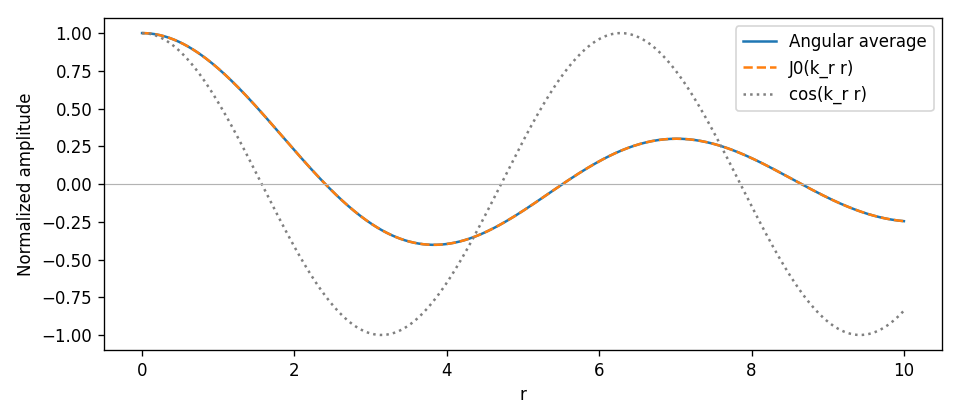

In [2]:
# Section 4: compare the cosine average over all directions with J0.
N = 128  # Number of directions: try 4, 16, and 128.
psi = np.linspace(0, 2*np.pi, N, endpoint=False)
mean_wave = np.cos(k_r * r[:, None] * np.cos(psi)).mean(axis=1)

plt.figure(figsize=(8, 3.5))
plt.plot(r, mean_wave, label="Angular average")
plt.plot(r, j0(k_r*r), "--", label="J0(k_r r)")
plt.plot(r, np.cos(k_r*r), ":", color="0.5", label="cos(k_r r)")
plt.axhline(0, color="0.7", linewidth=0.7)
plt.xlabel("r")
plt.ylabel("Normalized amplitude")
plt.legend()
plt.tight_layout()
plt.show()


## 5. Expressing TE modes with Bessel functions

For a TE mode in a circular waveguide, $E_z=0$, and the longitudinal magnetic field $H_z$ is the starting point. The Bessel-function representation of the longitudinal magnetic field used in a circular waveguide can be written as

$$
H_z(r,\phi,z)
=
H_0\,J_l(k_c r)\,[A\cos(l\phi)+B\sin(l\phi)]\,e^{-i\beta z}
$$

Using complex notation, we can also write

$$
H_z(r,\phi,z)\propto J_l(k_c r)e^{il\phi}e^{-i\beta z}
$$

Below, we retain the axial factor $e^{-i\beta z}$ as in the original text and focus on the transverse spatial distribution. Here, $k_c$ is the transverse eigenvalue in wave-number form, whose allowed values are selected by the boundary conditions.

This general expression should not be interpreted as a pure TE mode for every $l$ in an optical fiber.
Here, we focus on the fiber's **axisymmetric $TE_{0m}$ modes**, for which $l=0$.
The allowed wave numbers are determined by matching $H_z$ and $E_\phi$ continuously across the boundary between the core and the surrounding medium.
We do not work through the detailed boundary equations here.

For reference, the condition in the original text,

$$
J_l'(k_c a)=0
$$

and the statement that “the dominant mode is $TE_{11}$” apply to **a circular waveguide with perfectly conducting walls**.
We do not apply this condition directly to an optical fiber.

Source: [UT Austin, TE fields and boundary conditions in a dielectric waveguide, Eqs. (1386)–(1396)](https://farside.ph.utexas.edu/teaching/jk1/Electromagnetism/node118.html#:~:text=For%20a%20TE%20mode).


## 6. $TE_{0m}$: why $E_\phi\propto J_1$ appears

For an axisymmetric TE mode, $l=0$, so the longitudinal magnetic field is

$$
H_z(r,z)\propto J_0(k_c r)e^{-i\beta z}
$$

Maxwell's equations determine the transverse electric-field components of a TE mode from the radial derivative of $H_z$. In particular, for an axisymmetric mode,

$$
E_\phi \propto -\frac{\partial H_z}{\partial r}
$$

Therefore,

$$
E_\phi
\propto
-\frac{\partial}{\partial r}J_0(k_c r)
$$

Using the Bessel-function derivative identity

$$
\frac{dJ_0(x)}{dx}=-J_1(x)
$$

we obtain

$$
E_\phi\propto J_1(k_c r)
$$

Thus, in $TE_{0m}$, even though the longitudinal magnetic field has a $J_0$ profile, the transverse electric field $E_\phi$ has a $J_1$ profile.

These proportionalities omit common coefficients and phase factors to compare **the radial shapes**.
For $E_\phi$, the appearance of $J_1$ does not mean that the azimuthal mode number has changed to $l=1$.

Source: [NIST DLMF, derivative identity (10.6.3)](https://dlmf.nist.gov/10.6#E3).


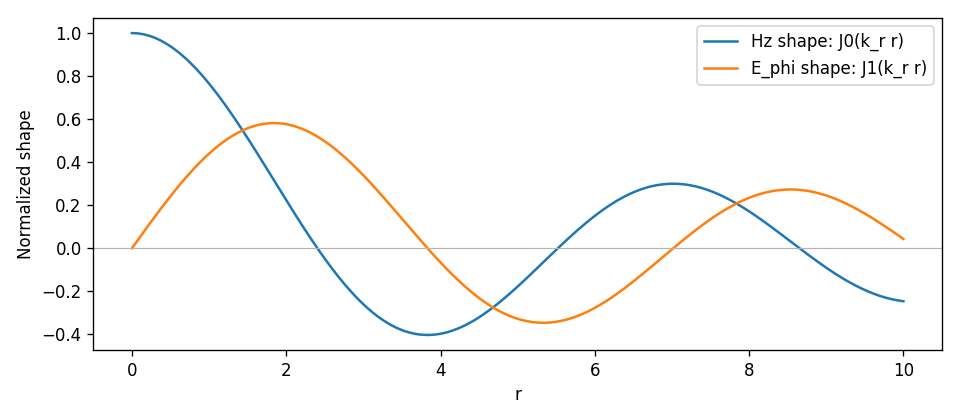

In [3]:
# Section 6: compare the spatial profiles of Hz and E_phi, omitting common coefficients.
plt.figure(figsize=(8, 3.5))
plt.plot(r, j0(k_r*r), label="Hz shape: J0(k_r r)")
plt.plot(r, j1(k_r*r), label="E_phi shape: J1(k_r r)")
plt.axhline(0, color="0.7", linewidth=0.7)
plt.xlabel("r")
plt.ylabel("Normalized shape")
plt.legend()
plt.tight_layout()
plt.show()


## 7. The meaning of $l$

In the complex representation of the longitudinal magnetic field,

$$
H_z(r,\phi,z)\propto J_l(k_r r)e^{il\phi}e^{-i\beta z}
$$

$l$ is the **azimuthal mode number**.

- For $l=0$, $e^{i0\phi}=1$, so this scalar field component does not depend on the azimuthal angle $\phi$.
- For $l=1$, the factor is $e^{i\phi}$; as $\phi$ increases by $2\pi$, the complex phase changes by $2\pi$.
- For $l=2$, the factor is $e^{i2\phi}$; over one full turn, the complex phase changes by $4\pi$.

In this sense, $l$ appears to correspond to a “phase winding number” in complex notation. However, TE/TM modes in circular waveguides are often written using the real functions

$$
\cos(l\phi),\qquad \sin(l\phi)
$$

so **azimuthal mode number** is the safest name. In other words, $l$ describes **the order of the angular dependence in the cross section**, rather than the **polarization direction**.

The electric field of an axisymmetric TE mode points in the $\hat{\boldsymbol\phi}$ direction. Even if the component $E_\phi(r)$ is independent of the azimuthal angle, the vector direction changes around the circumference.


## 8. Summary

The TE modes discussed here satisfy

$$
E_z=0,\qquad H_z\neq 0
$$

Their transverse structure can be understood as a superposition of plane-wave components. As a result of this cylindrically symmetric superposition, the radial dependence is expressed by the Bessel function $J_l$. In particular, an equally weighted superposition over all azimuthal angles gives $J_0$, while an azimuthal phase weight $e^{il\psi}$ gives $J_l(k_r r)e^{il\phi}$. For an axisymmetric TE mode, the longitudinal magnetic field $H_z$ is the starting point. In $TE_{0m}$, $H_z\propto J_0$, and the transverse electric field derived from it satisfies

$$
E_\phi\propto J_1
$$

Thus, $l$ is **an index describing the mode's azimuthal dependence**, rather than its polarization.
